# Phát hiện biên đường: HSV → Canny → Hough

Notebook chạy trọn chuỗi xử lý của đồ án trên 50 ảnh trong `dataset/images`, từ đầu đến cuối, và hiển thị kết quả sau mỗi bước:

1. **Tiền xử lý HSV**: resize 960×540 → RGB sang HSV → lọc vạch trắng/vàng → Gaussian → ảnh xám.
2. **Canny** (cài bằng NumPy): Gaussian → Sobel → NMS → ngưỡng kép + hysteresis, tham số `(50, 150)`, σ = 1,4.
3. **Hough**: ROI hình thang → P-Hough → lọc độ dốc trái/phải → hồi quy có trọng số → đa giác mặt đường.
4. **Đánh giá**: IoU và MAE so với ground truth, tổng hợp theo nhóm `normal / curved / adverse`.

Code thuật toán chép nguyên từ `preprocessing.py`, `canny.py`, `hough.py`, nên notebook chạy độc lập, không cần import các file đó.

**Cách chạy:** mở notebook ở thư mục gốc dự án (hoặc trên Colab, xem ô đầu tiên) rồi chọn *Run All*. Ô đầu tiên mở hộp thoại chọn một hoặc nhiều ảnh làm đầu vào; bấm *Cancel* (hoặc chạy trên Colab) thì dùng cả 50 ảnh của dataset. Ảnh không có ground truth vẫn chạy đủ các bước, chỉ bị bỏ qua ở bước đánh giá. Kết quả ghi vào `outputs/pipeline_notebook/`, không ghi đè thư mục `outputs/` của từng phần.

In [1]:
from dataclasses import asdict, dataclass
from pathlib import Path
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter, ImageOps

# Neu chay tren Google Colab voi Drive, bo dau # o hai dong sau.
# from google.colab import drive
# drive.mount('/content/drive')

candidates = [Path.cwd(), Path.cwd().parent, Path('/content/Bai_Tap_Lon'), Path('/content/drive/MyDrive/Bai_Tap_Lon')]
ROOT = next((p for p in candidates if (p / 'dataset' / 'images').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Khong tim thay dataset/images. Hay mount Drive hoac sua candidates.')

IMAGE_DIR = ROOT / 'dataset' / 'images'
GT_DIR = ROOT / 'dataset' / 'ground_truth'
OUT = ROOT / 'outputs' / 'pipeline_notebook'
GROUPS = ['normal', 'curved', 'adverse']
SAMPLES = [('normal', 'normal_05'), ('curved', 'curved_05'), ('adverse', 'adverse_13')]

image_paths = sorted(p for g in GROUPS for p in (IMAGE_DIR / g).iterdir()
                     if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'})

# Hop thoai chon anh dau vao. Bam Cancel, hoac moi truong khong co man hinh (Colab), thi dung ca dataset.
try:
    import tkinter as tk
    from tkinter import filedialog
    tk_root = tk.Tk()
    tk_root.withdraw()
    tk_root.attributes('-topmost', True)  # de hop thoai khong bi an sau cua so Jupyter
    picked = filedialog.askopenfilenames(parent=tk_root, title='Chon mot hoac nhieu anh', initialdir=IMAGE_DIR,
                                         filetypes=[('Anh', '*.jpg *.jpeg *.png *.bmp *.webp'), ('Tat ca', '*.*')])
    tk_root.destroy()
except Exception:
    picked = ()
if picked:
    image_paths = [Path(p) for p in picked]

NAMES = [(p.parent.name, p.stem) for p in image_paths]
# Anh mau de ve hinh: giu anh mau mac dinh neu co trong danh sach, neu khong lay toi da 3 anh dau
SAMPLES = [k for k in SAMPLES if k in NAMES] or NAMES[:3]
print('ROOT =', ROOT)
print('So anh =', len(NAMES), {g: sum(1 for x, _ in NAMES if x == g) for g in GROUPS})


def show(rows, titles, figsize_per=(5, 2.9)):
    # Ve luoi anh: moi hang mot anh mau, moi cot mot buoc
    fig, axes = plt.subplots(len(rows), len(titles), figsize=(figsize_per[0] * len(titles), figsize_per[1] * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (label, panels) in enumerate(rows):
        for c, img in enumerate(panels):
            axes[r, c].imshow(img, cmap='gray' if img.ndim == 2 else None)
            axes[r, c].set_title(f'{label} | {titles[c]}', fontsize=10)
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.show()

ROOT = D:\PrjIP\canny-hough
So anh = 50 {'normal': 18, 'curved': 12, 'adverse': 20}


## Bước 1. Tiền xử lý HSV

Thay bước `RGB → grayscale` của bài base (Belhadri et al., 2026) bằng lọc màu trong không gian HSV:

- **Vạch trắng:** S ≤ 80 và V ≥ 170.
- **Vạch vàng:** 15 ≤ H ≤ 40, S ≥ 70, V ≥ 90 (H theo quy ước OpenCV, thang 0–179).

Pixel không thuộc hai nhóm trên bị đưa về đen. Ảnh sau đó được làm mờ Gaussian (bán kính 1,2) rồi chuyển sang ảnh xám, `canny_input`, làm đầu vào cho Canny.

In [2]:
@dataclass(frozen=True)
class PreprocessConfig:
    target_width: int = 960
    target_height: int = 540
    white_saturation_max: int = 80
    white_value_min: int = 170
    yellow_hue_min: int = 15
    yellow_hue_max: int = 40
    yellow_saturation_min: int = 70
    yellow_value_min: int = 90
    gaussian_radius: float = 1.2


@dataclass(frozen=True)
class PreprocessResult:
    resized_rgb: np.ndarray
    hsv: np.ndarray
    color_mask: np.ndarray
    color_filtered_rgb: np.ndarray
    gaussian_rgb: np.ndarray
    canny_input: np.ndarray


def _validate_rgb(rgb):
    array = np.asarray(rgb)
    if array.ndim != 3 or array.shape[2] != 3:
        raise ValueError('Anh dau vao phai co dang H x W x 3')
    if array.dtype != np.uint8:
        if np.issubdtype(array.dtype, np.floating) and array.size:
            if float(array.min()) >= 0.0 and float(array.max()) <= 1.0:
                array = np.rint(array * 255.0)
        array = np.clip(array, 0, 255).astype(np.uint8)
    return array


def resize_rgb(rgb, width, height):
    image = Image.fromarray(_validate_rgb(rgb), mode='RGB')
    return np.asarray(image.resize((width, height), Image.Resampling.LANCZOS))


def rgb_to_hsv_opencv(rgb):
    # H in [0,179], S,V in [0,255]
    source = _validate_rgb(rgb).astype(np.float32) / 255.0
    red, green, blue = source[..., 0], source[..., 1], source[..., 2]
    maximum = source.max(axis=2)
    minimum = source.min(axis=2)
    delta = maximum - minimum

    hue_degrees = np.zeros_like(maximum)
    non_gray = delta > 1e-7
    red_max = non_gray & (maximum == red)
    green_max = non_gray & (maximum == green)
    blue_max = non_gray & (maximum == blue)
    hue_degrees[red_max] = (60.0 * ((green[red_max] - blue[red_max]) / delta[red_max])) % 360.0
    hue_degrees[green_max] = 60.0 * ((blue[green_max] - red[green_max]) / delta[green_max] + 2.0)
    hue_degrees[blue_max] = 60.0 * ((red[blue_max] - green[blue_max]) / delta[blue_max] + 4.0)

    saturation = np.zeros_like(maximum)
    non_black = maximum > 1e-7
    saturation[non_black] = delta[non_black] / maximum[non_black]

    hue = np.clip(np.rint(hue_degrees / 2.0), 0, 179).astype(np.uint8)
    sat = np.clip(np.rint(saturation * 255.0), 0, 255).astype(np.uint8)
    value = np.clip(np.rint(maximum * 255.0), 0, 255).astype(np.uint8)
    return np.stack((hue, sat, value), axis=2)


def lane_marking_mask(hsv, white_saturation_max=80, white_value_min=170, yellow_hue_min=15,
                      yellow_hue_max=40, yellow_saturation_min=70, yellow_value_min=90):
    hue, saturation, value = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    white = (saturation <= white_saturation_max) & (value >= white_value_min)
    yellow = ((hue >= yellow_hue_min) & (hue <= yellow_hue_max)
              & (saturation >= yellow_saturation_min) & (value >= yellow_value_min))
    return np.where(white | yellow, 255, 0).astype(np.uint8)


def apply_binary_mask(rgb, mask):
    return np.where(mask[..., None] > 0, _validate_rgb(rgb), 0).astype(np.uint8)


def gaussian_blur_rgb(rgb, radius):
    image = Image.fromarray(_validate_rgb(rgb), mode='RGB')
    return np.asarray(image.filter(ImageFilter.GaussianBlur(radius=radius)))


def rgb_to_gray(rgb):
    source = _validate_rgb(rgb).astype(np.float32)
    gray = 0.299 * source[..., 0] + 0.587 * source[..., 1] + 0.114 * source[..., 2]
    return np.clip(np.rint(gray), 0, 255).astype(np.uint8)


def preprocess_rgb(rgb, cfg=PreprocessConfig()):
    resized = resize_rgb(rgb, cfg.target_width, cfg.target_height)
    hsv = rgb_to_hsv_opencv(resized)
    color_mask = lane_marking_mask(hsv, cfg.white_saturation_max, cfg.white_value_min, cfg.yellow_hue_min,
                                   cfg.yellow_hue_max, cfg.yellow_saturation_min, cfg.yellow_value_min)
    filtered = apply_binary_mask(resized, color_mask)
    gaussian = gaussian_blur_rgb(filtered, cfg.gaussian_radius)
    return PreprocessResult(resized, hsv, color_mask, filtered, gaussian, rgb_to_gray(gaussian))


def read_rgb(path):
    with Image.open(path) as opened:
        return np.asarray(ImageOps.exif_transpose(opened).convert('RGB'))


print(asdict(PreprocessConfig()))

{'target_width': 960, 'target_height': 540, 'white_saturation_max': 80, 'white_value_min': 170, 'yellow_hue_min': 15, 'yellow_hue_max': 40, 'yellow_saturation_min': 70, 'yellow_value_min': 90, 'gaussian_radius': 1.2}


Da xu ly 50 anh. Ti le pixel giu lai sau loc mau trung binh: 14.77%


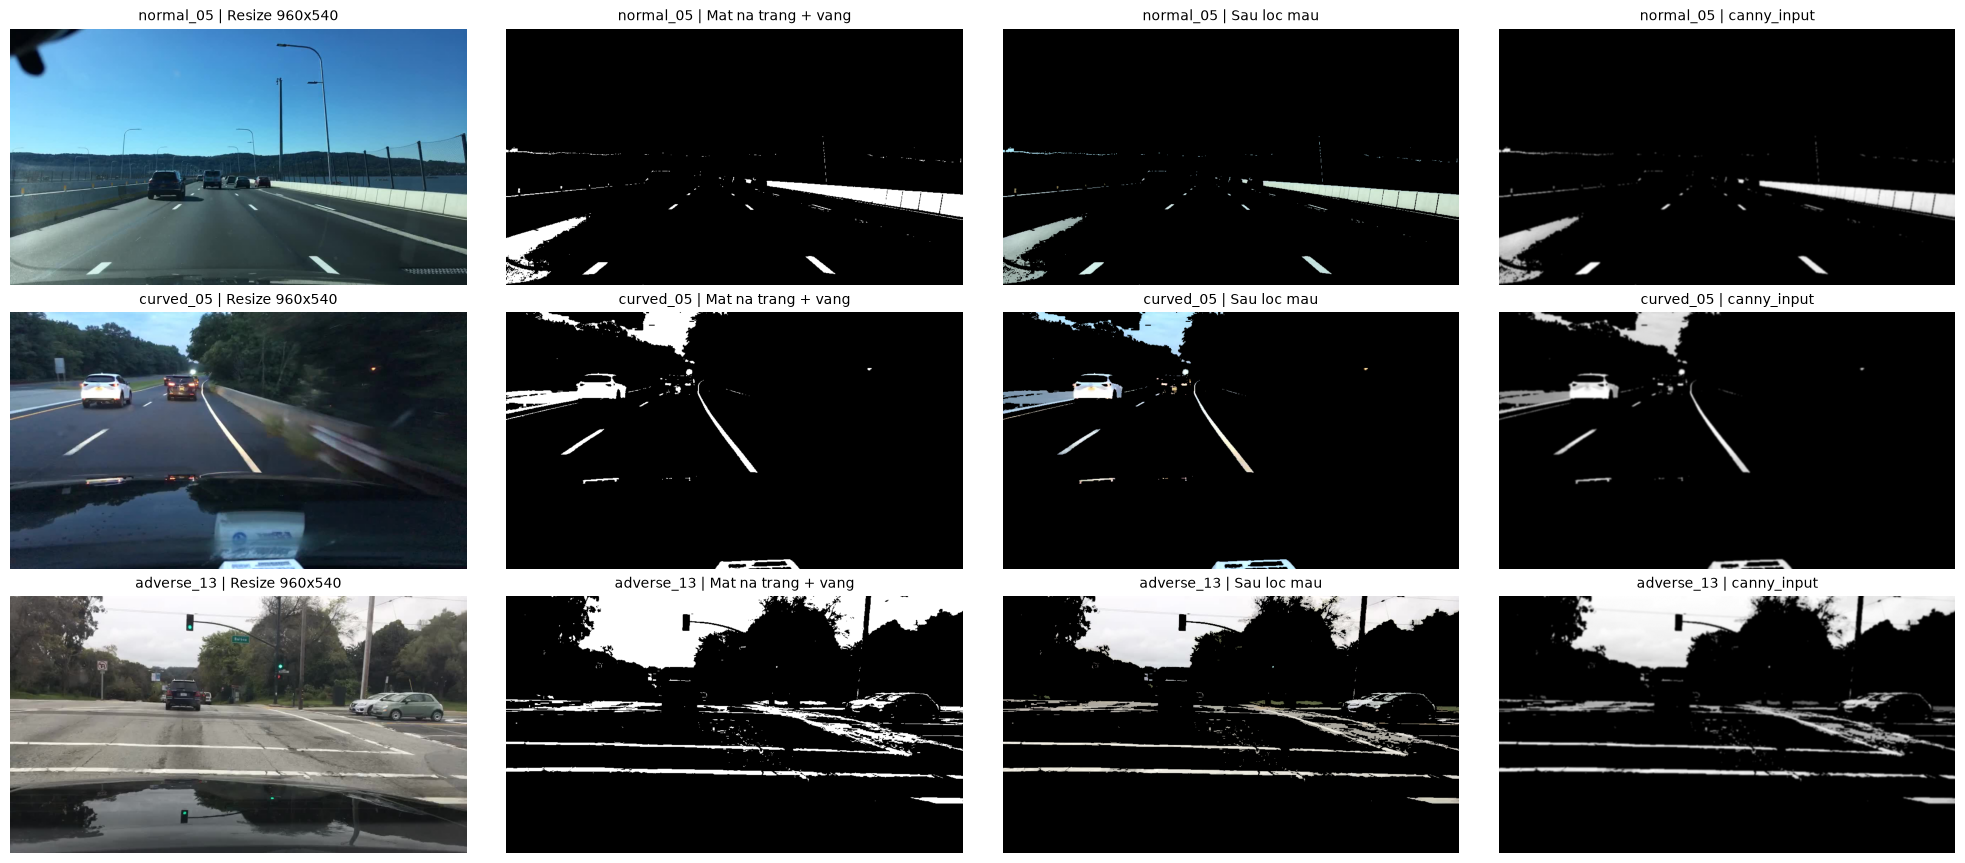

In [3]:
pre = {}
for path, key in zip(image_paths, NAMES):
    pre[key] = preprocess_rgb(read_rgb(path))
    rel = Path(*key).with_suffix('.png')
    for sub, arr in [('canny_input', pre[key].canny_input), ('resized', pre[key].resized_rgb)]:
        (OUT / sub / rel).parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(arr).save(OUT / sub / rel)

ratio = np.mean([np.mean(r.color_mask > 0) for r in pre.values()])
print(f'Da xu ly {len(pre)} anh. Ti le pixel giu lai sau loc mau trung binh: {ratio:.2%}')

show([(n, [pre[(g, n)].resized_rgb, pre[(g, n)].color_mask, pre[(g, n)].color_filtered_rgb, pre[(g, n)].canny_input])
      for g, n in SAMPLES],
     ['Resize 960x540', 'Mat na trang + vang', 'Sau loc mau', 'canny_input'])

## Bước 2. Canny

Cài bằng NumPy theo 4 bước:

1. **Làm mờ Gaussian** 5×5, σ = 1,4, dùng tích chập tách được (lọc theo hàng rồi theo cột).
2. **Sobel**: tính độ lớn gradient (chuẩn L2) và hướng gradient.
3. **Non-maximum suppression**: hướng được làm tròn về 0°, 45°, 90°, 135°. Chỉ giữ pixel lớn hơn hai láng giềng dọc theo hướng gradient.
4. **Ngưỡng kép + hysteresis** `(50, 150)`: giữ cạnh mạnh, rồi lan dần sang các cạnh yếu nối liền với chúng.

Tham số `(50, 150, σ = 1,4)` là bộ tham số được chọn ở phần Canny của nhóm.

In [4]:
def gaussian_kernel(size, sigma):
    ax = np.arange(size) - size // 2
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    return g / g.sum()


def convolve_separable(img, k):
    r = len(k) // 2
    p = np.pad(img, r, mode='reflect')
    tmp = sum(k[i] * p[:, i:i + img.shape[1]] for i in range(len(k)))
    return sum(k[i] * tmp[i:i + img.shape[0], :] for i in range(len(k)))


def gaussian_smooth(img, size=5, sigma=1.4):
    return convolve_separable(img.astype(np.float64), gaussian_kernel(size, sigma))


def sobel_gradient(img, l2=True):
    p = np.pad(img, 1, mode='reflect')
    h, w = img.shape
    a = lambda dy, dx: p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
    gx = (a(-1, 1) + 2 * a(0, 1) + a(1, 1)) - (a(-1, -1) + 2 * a(0, -1) + a(1, -1))
    gy = (a(1, -1) + 2 * a(1, 0) + a(1, 1)) - (a(-1, -1) + 2 * a(-1, 0) + a(-1, 1))
    mag = np.hypot(gx, gy) if l2 else np.abs(gx) + np.abs(gy)
    return mag, np.arctan2(gy, gx)


def non_max_suppression(mag, theta):
    h, w = mag.shape
    p = np.pad(mag, 1)
    a = lambda dy, dx: p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
    ang = np.rad2deg(theta) % 180
    n1 = np.zeros_like(mag)
    n2 = np.zeros_like(mag)
    for lo, hi, dy, dx in [(0, 22.5, 0, 1), (22.5, 67.5, 1, 1), (67.5, 112.5, 1, 0), (112.5, 157.5, 1, -1), (157.5, 180.01, 0, 1)]:
        m = (ang >= lo) & (ang < hi)
        n1[m] = a(dy, dx)[m]
        n2[m] = a(-dy, -dx)[m]
    return np.where((mag > n1) & (mag >= n2), mag, 0)


def double_threshold_hysteresis(nms, low, high):
    strong = nms >= high
    weak = nms >= low
    edges = strong.copy()
    while True:
        p = np.pad(edges, 1)
        near = np.zeros_like(edges)
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                near |= p[1 + dy:1 + dy + edges.shape[0], 1 + dx:1 + dx + edges.shape[1]]
        new = weak & near
        if (new == edges).all():
            return (edges * 255).astype(np.uint8)
        edges = new


def canny_edges(img, low, high, sigma, size=5, l2=True):
    smooth = gaussian_smooth(img, size, sigma)
    mag, theta = sobel_gradient(smooth, l2)
    return double_threshold_hysteresis(non_max_suppression(mag, theta), low, high)

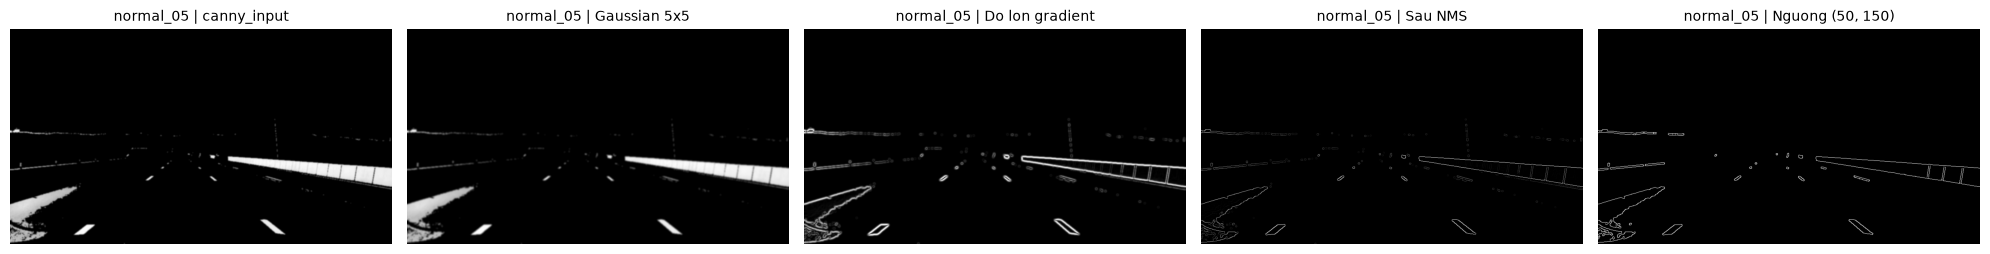

In [5]:
# Cac buoc trung gian cua Canny tren mot anh mau
img = pre[SAMPLES[0]].canny_input
smooth = gaussian_smooth(img, 5, 1.4)
mag, theta = sobel_gradient(smooth)
nms = non_max_suppression(mag, theta)
show([(SAMPLES[0][1], [img, smooth, mag, nms, double_threshold_hysteresis(nms, 50, 150)])],
     ['canny_input', 'Gaussian 5x5', 'Do lon gradient', 'Sau NMS', 'Nguong (50, 150)'], figsize_per=(4, 2.5))

Da chay Canny 50 anh trong 12.8 s. Mat do canh trung binh: 2.06%


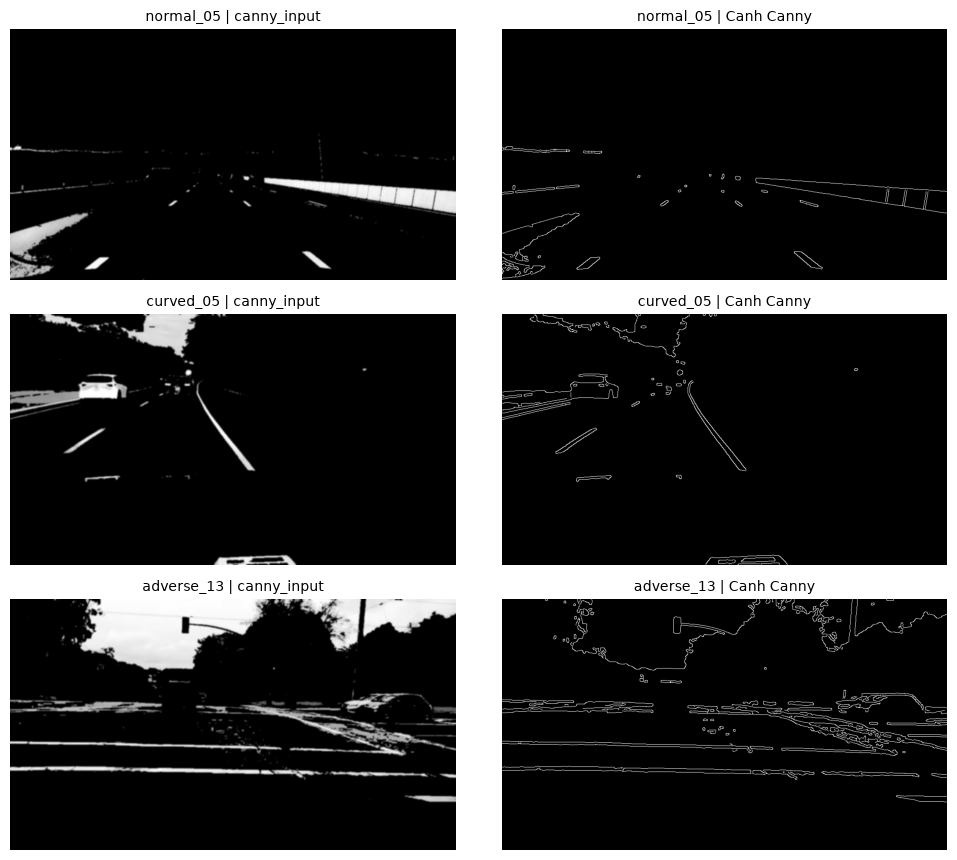

In [6]:
edges = {}
t0 = time.perf_counter()
for key in NAMES:
    edges[key] = canny_edges(pre[key].canny_input, 50, 150, 1.4)
    path = OUT / 'edges' / Path(*key).with_suffix('.png')
    path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(path), edges[key])
print(f'Da chay Canny {len(edges)} anh trong {time.perf_counter() - t0:.1f} s. '
      f'Mat do canh trung binh: {np.mean([np.mean(e > 0) for e in edges.values()]):.2%}')

show([(n, [pre[(g, n)].canny_input, edges[(g, n)]]) for g, n in SAMPLES], ['canny_input', 'Canh Canny'])

## Bước 3. Biến đổi Hough và hậu xử lý

1. **ROI hình thang**: đáy trên rộng 35% W ở độ cao 48% H, đáy dưới rộng 98% W ở độ cao 98% H. ROI loại bỏ bầu trời và nắp capo.
2. **P-Hough** (`cv2.HoughLinesP`): ρ = 1 px, θ = 1°, ngưỡng 25 phiếu, đoạn dài tối thiểu 25 px, khoảng hở tối đa 25 px.
3. **Lọc độ dốc** `0,3 ≤ |m| ≤ 4`. Đoạn có `m < 0` và nằm ở nửa trái được xếp vào biên trái, đoạn có `m > 0` và nằm ở nửa phải được xếp vào biên phải.
4. **Hồi quy có trọng số** `x = k·y + b`, trọng số là chiều dài đoạn, để tìm một đường đại diện cho mỗi bên.
5. **Đa giác mặt đường**: tạo được khi bắt đủ cả hai biên.

In [7]:
@dataclass(frozen=True)
class HoughConfig:
    roi_top_width_ratio: float = 0.35
    roi_bottom_width_ratio: float = 0.98
    roi_top_y_ratio: float = 0.48
    roi_bottom_y_ratio: float = 0.98
    rho: float = 1.0
    theta: float = np.pi / 180.0
    threshold: int = 25
    min_line_length: float = 25.0
    max_line_gap: float = 25.0
    min_abs_slope: float = 0.30
    max_abs_slope: float = 4.00


@dataclass(frozen=True)
class HoughResult:
    left_line: tuple | None       # ((x_bottom, y_bottom), (x_top, y_top))
    right_line: tuple | None
    polygon: np.ndarray | None    # (4, 2) da giac mat duong
    raw_lines: np.ndarray         # (N, 4) doan P-Hough
    left_segments: np.ndarray
    right_segments: np.ndarray
    roi_mask: np.ndarray


def get_trapezoid_vertices(height, width, cfg):
    center_x = width / 2.0
    top_y = int(height * cfg.roi_top_y_ratio)
    bottom_y = int(height * cfg.roi_bottom_y_ratio)
    half_top_w = (width * cfg.roi_top_width_ratio) / 2.0
    half_bottom_w = (width * cfg.roi_bottom_width_ratio) / 2.0
    top_left = (int(max(0, center_x - half_top_w)), top_y)
    top_right = (int(min(width - 1, center_x + half_top_w)), top_y)
    bottom_right = (int(min(width - 1, center_x + half_bottom_w)), bottom_y)
    bottom_left = (int(max(0, center_x - half_bottom_w)), bottom_y)
    return np.array([[bottom_left, top_left, top_right, bottom_right]], dtype=np.int32)


def apply_roi(edges, vertices):
    mask = np.zeros_like(edges, dtype=np.uint8)
    cv2.fillPoly(mask, vertices, 255)
    return cv2.bitwise_and(edges, mask), mask


def detect_hough_lines_p(roi_edges, cfg):
    lines = cv2.HoughLinesP(roi_edges, rho=cfg.rho, theta=cfg.theta, threshold=cfg.threshold,
                            minLineLength=cfg.min_line_length, maxLineGap=cfg.max_line_gap)
    if lines is None:
        return np.empty((0, 4), dtype=np.int32)
    return lines.reshape(-1, 4).astype(np.int32)


def split_left_right_segments(lines, width, cfg):
    # He toa do anh, y huong xuong: bien trai co slope < 0, bien phai co slope > 0
    left_list, right_list = [], []
    for seg in lines:
        x1, y1, x2, y2 = seg
        dx, dy = x2 - x1, y2 - y1
        if dx == 0:
            continue
        slope = dy / dx
        if not (cfg.min_abs_slope <= abs(slope) <= cfg.max_abs_slope):
            continue
        x_mid = (x1 + x2) / 2.0
        if slope < 0 and x_mid < width * 0.65:
            left_list.append(seg)
        elif slope > 0 and x_mid > width * 0.35:
            right_list.append(seg)
    empty = np.empty((0, 4), dtype=np.int32)
    return (np.array(left_list, dtype=np.int32) if left_list else empty,
            np.array(right_list, dtype=np.int32) if right_list else empty)


def fit_boundary_line(segments, y_bottom, y_top):
    # Hoi quy x = k*y + b co trong so theo chieu dai doan
    if len(segments) == 0:
        return None
    dx = segments[:, 2] - segments[:, 0]
    dy = segments[:, 3] - segments[:, 1]
    lengths = np.hypot(dx, dy)
    valid = lengths > 1e-3
    if not np.any(valid):
        return None
    segs, weights = segments[valid], lengths[valid]
    x = np.concatenate([segs[:, 0], segs[:, 2]])
    y = np.concatenate([segs[:, 1], segs[:, 3]])
    w = np.concatenate([weights, weights])
    total_w = np.sum(w)
    if total_w <= 0:
        return None
    mean_y = np.sum(w * y) / total_w
    mean_x = np.sum(w * x) / total_w
    var_y = np.sum(w * (y - mean_y) ** 2)
    if var_y < 1e-5:
        return None
    k = np.sum(w * (y - mean_y) * (x - mean_x)) / var_y
    b = mean_x - k * mean_y
    return ((int(round(k * y_bottom + b)), y_bottom), (int(round(k * y_top + b)), y_top))


def create_road_polygon(left_line, right_line):
    if left_line is None or right_line is None:
        return None
    (xlb, ylb), (xlt, ylt) = left_line
    (xrb, yrb), (xrt, yrt) = right_line
    return np.array([[xlb, ylb], [xlt, ylt], [xrt, yrt], [xrb, yrb]], dtype=np.int32)


def detect_road_boundaries(edges, cfg=HoughConfig()):
    height, width = edges.shape[:2]
    roi_edges, roi_mask = apply_roi(edges, get_trapezoid_vertices(height, width, cfg))
    raw_lines = detect_hough_lines_p(roi_edges, cfg)
    left_segs, right_segs = split_left_right_segments(raw_lines, width, cfg)
    y_bottom, y_top = int(height * cfg.roi_bottom_y_ratio), int(height * cfg.roi_top_y_ratio)
    left_line = fit_boundary_line(left_segs, y_bottom, y_top)
    right_line = fit_boundary_line(right_segs, y_bottom, y_top)
    return HoughResult(left_line, right_line, create_road_polygon(left_line, right_line),
                       raw_lines, left_segs, right_segs, roi_mask)


def draw_hough_visualization(background_rgb, result, draw_raw_lines=False, draw_roi=True):
    canvas = background_rgb.copy()
    if result.polygon is not None:
        overlay = canvas.copy()
        cv2.fillPoly(overlay, [result.polygon], (0, 200, 0))
        cv2.addWeighted(overlay, 0.25, canvas, 0.75, 0, canvas)
    if draw_roi:
        contours, _ = cv2.findContours(result.roi_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, contours, -1, (255, 255, 0), 1, lineType=cv2.LINE_AA)
    if draw_raw_lines:
        for x1, y1, x2, y2 in result.left_segments:
            cv2.line(canvas, (x1, y1), (x2, y2), (255, 100, 100), 1, lineType=cv2.LINE_AA)
        for x1, y1, x2, y2 in result.right_segments:
            cv2.line(canvas, (x1, y1), (x2, y2), (100, 100, 255), 1, lineType=cv2.LINE_AA)
    if result.left_line is not None:
        cv2.line(canvas, *result.left_line, (255, 0, 0), 3, lineType=cv2.LINE_AA)
    if result.right_line is not None:
        cv2.line(canvas, *result.right_line, (0, 0, 255), 3, lineType=cv2.LINE_AA)
    return canvas

Da chay Hough 50 anh, ket qua ve trong D:\PrjIP\canny-hough\outputs\pipeline_notebook\hough


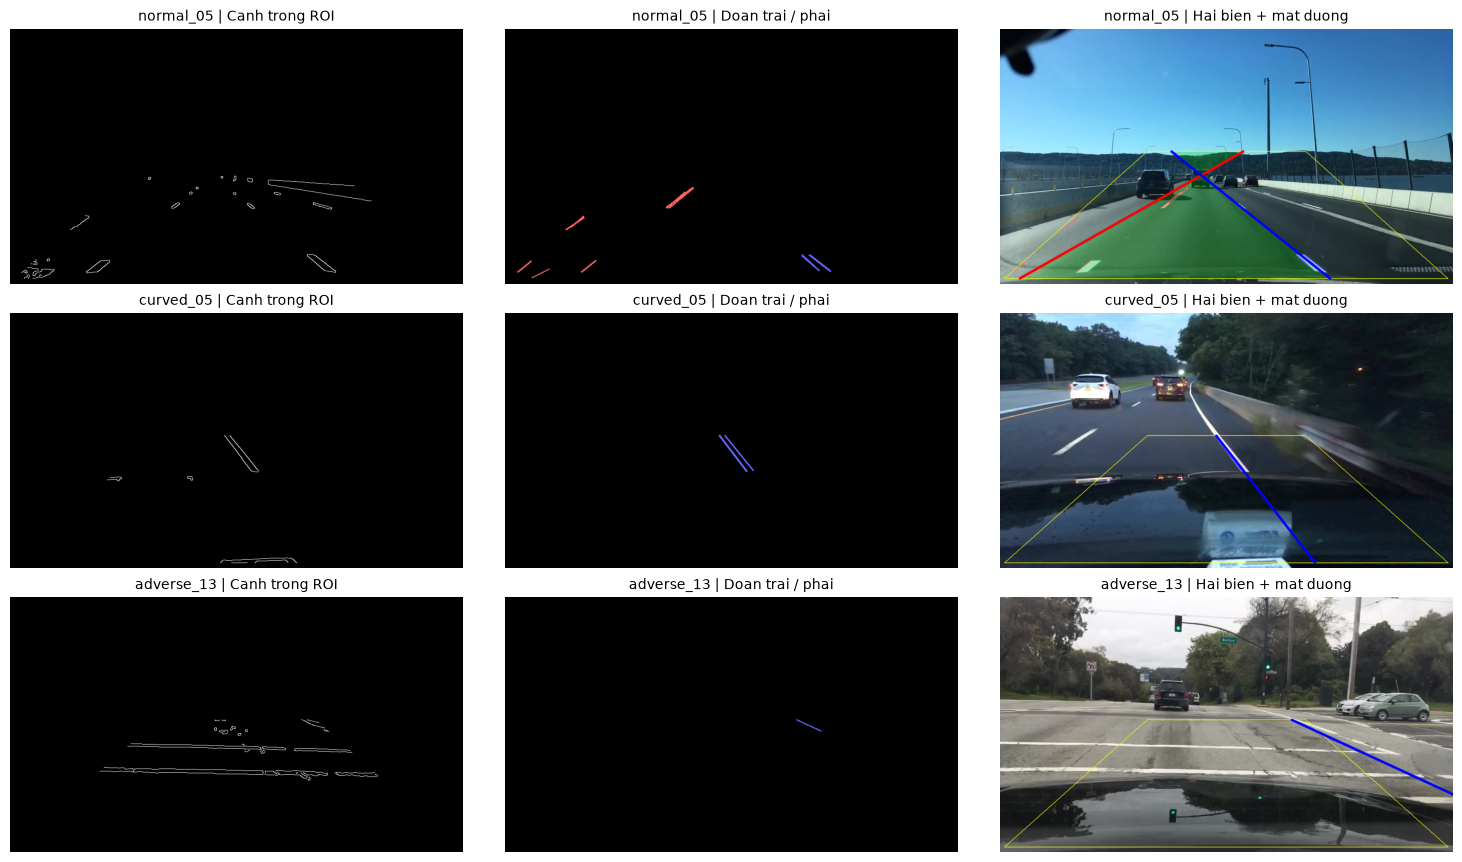

In [8]:
hough = {}
for key in NAMES:
    hough[key] = detect_road_boundaries(edges[key])
    vis = draw_hough_visualization(pre[key].resized_rgb, hough[key])
    path = OUT / 'hough' / Path(*key).with_suffix('.png')
    path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(path), cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))
print('Da chay Hough', len(hough), 'anh, ket qua ve trong', OUT / 'hough')


def segments_canvas(r, shape):
    # Cung mau voi duong bien o cot cuoi: doan trai do, doan phai xanh
    canvas = np.zeros((*shape, 3), dtype=np.uint8)
    for x1, y1, x2, y2 in r.left_segments:
        cv2.line(canvas, (x1, y1), (x2, y2), (255, 100, 100), 2)
    for x1, y1, x2, y2 in r.right_segments:
        cv2.line(canvas, (x1, y1), (x2, y2), (100, 100, 255), 2)
    return canvas


show([(n, [cv2.bitwise_and(edges[(g, n)], hough[(g, n)].roi_mask),
           segments_canvas(hough[(g, n)], edges[(g, n)].shape),
           draw_hough_visualization(pre[(g, n)].resized_rgb, hough[(g, n)], draw_raw_lines=True)])
      for g, n in SAMPLES],
     ['Canh trong ROI', 'Doan trai / phai', 'Hai bien + mat duong'])

## Bước 4. Đánh giá với ground truth

Ground truth là mặt nạ **vùng mặt đường**, được resize về 960×540.

- **IoU**: độ chồng lấp giữa đa giác dự đoán và vùng mặt đường thật. Chỉ tính trên ảnh bắt đủ hai biên.
- **MAE (px)**: sai số vị trí biên. Tại 3 hàng ngang `y = 60%, 75%, 90% H`, đo khoảng cách từ biên trái/phải dự đoán tới mép trái/phải của vùng ground truth, rồi lấy trung bình.

In [9]:
W, H = 960, 540
records = []
for g, n in NAMES:
    r = hough[(g, n)]
    gt_path = GT_DIR / g / f'{n}.png'
    if not gt_path.exists():  # anh tu chon ngoai dataset, khong co ground truth
        print('Bo qua danh gia (khong co ground truth):', g, n)
        continue
    gt = cv2.resize(cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE), (W, H),
                    interpolation=cv2.INTER_NEAREST) > 0

    iou = 0.0
    if r.polygon is not None:
        mask = np.zeros((H, W), dtype=np.uint8)
        cv2.fillPoly(mask, [r.polygon], 1)
        union = np.logical_or(mask > 0, gt).sum()
        iou = float(np.logical_and(mask > 0, gt).sum() / union) if union > 0 else 0.0

    mae = None
    if r.left_line is not None and r.right_line is not None:
        (xl_b, yl_b), (xl_t, yl_t) = r.left_line
        (xr_b, yr_b), (xr_t, yr_t) = r.right_line
        kl = (xl_b - xl_t) / (yl_b - yl_t) if yl_b != yl_t else 0.0
        kr = (xr_b - xr_t) / (yr_b - yr_t) if yr_b != yr_t else 0.0
        errors = []
        for ratio in (0.60, 0.75, 0.90):
            yk = int(H * ratio)
            row = np.where(gt[yk, :])[0]
            if len(row) == 0:
                continue
            errors.append(abs(xl_t + kl * (yk - yl_t) - row[0]) + abs(xr_t + kr * (yk - yr_t) - row[-1]))
        if errors:
            mae = float(np.mean(errors) / 2.0)

    records.append(dict(group=g, image=n, raw_lines=len(r.raw_lines),
                        left_found=int(r.left_line is not None), right_found=int(r.right_line is not None),
                        both_found=int(r.polygon is not None), iou=iou, mae=mae))

df = pd.DataFrame(records, columns=['group', 'image', 'raw_lines', 'left_found', 'right_found',
                                   'both_found', 'iou', 'mae'])
df.to_csv(OUT / 'results.csv', index=False)

summary = []
for g in GROUPS + ['all']:
    sub = df if g == 'all' else df[df['group'] == g]
    ok = sub[sub['both_found'] == 1]
    summary.append({
        'Nhom': g,
        'So anh': len(sub),
        'Doan P-Hough TB': round(sub['raw_lines'].mean(), 1),
        'Bat trai (%)': round(sub['left_found'].mean() * 100, 1),
        'Bat phai (%)': round(sub['right_found'].mean() * 100, 1),
        'Bat ca 2 bien (%)': round(sub['both_found'].mean() * 100, 1),
        'IoU TB (anh dat)': round(ok['iou'].mean(), 4),
        'MAE TB (px)': round(ok['mae'].mean(), 2),
    })
print('Chi tiet tung anh luu tai', OUT / 'results.csv')
pd.DataFrame(summary)

Chi tiet tung anh luu tai D:\PrjIP\canny-hough\outputs\pipeline_notebook\results.csv


,Nhom,So anh,Doan P-Hough TB,Bat trai (%),Bat phai (%),Bat ca 2 bien (%),IoU TB (anh dat),MAE TB (px)
0,normal,18,57.3,72.2,66.7,50.0,0.2994,213.70
1,curved,12,51.2,66.7,75.0,50.0,0.3809,177.20
2,adverse,20,38.2,80.0,75.0,60.0,0.2923,279.67
3,all,50,48.2,74.0,72.0,54.0,0.3144,234.91
